## Vocabulary Differences Across BBC News Categories
# P3
- Author: [Agnes Mrutu](https://github.com/amrutu75/)
- Repository: [nlp-03-text-exploratory-custom](https://github.com/amrutu75/nlp-03-text-exploration-custom)
- Purpose: To examine vocabulary patterns within BBC News articles and identify the words that best distinguish Business, Sports, Politics, Technology, and Entertainment   categories.
- Date: 08-November-2026


## Section 1. Setup and Imports

In [48]:
from collections import Counter
from itertools import pairwise
from pathlib import Path
import re

import matplotlib.pyplot as plt
import polars as pl
from wordcloud import WordCloud

print("Imports complete.")
print("WordCloud import complete.")

Imports complete.
WordCloud import complete.


## Section 2. Read the Text Data

In [34]:
# Section 2 Python cell

# In notebooks, start with the current working directory
# where the notebook is located.


NOTEBOOKS_PATH: Path = Path.cwd()
ROOT_PATH: Path = NOTEBOOKS_PATH.parent

DATA_PATH: Path = ROOT_PATH / "data"
NOTEBOOKS_PATH: Path = ROOT_PATH / "notebooks"
SCRIPTS_PATH: Path = ROOT_PATH / "scripts"

# Choose a text file to analyze.
# Each line is treated as one text record.
input_path: Path = DATA_PATH / "bbc-text.csv"

# Read all lines from the file.
text_list: list[str] = input_path.read_text(encoding="utf-8").splitlines()

# Remove blank lines.
text_list = [line.strip() for line in text_list if line.strip()]

print("Data loaded successfully.")
print(f"Loaded {len(text_list):,} text records.")

# Combine all text rows into one large string for simple preprocessing.
raw_text: str = " ".join(text_list)

print(f"Raw text length: {len(raw_text):,} characters")
print("First 500 characters of raw text:")
print(raw_text[:500])

Data loaded successfully.
Loaded 100 text records.
Raw text length: 202,460 characters
First 500 characters of raw text:
category,text tech,tv future in the hands of viewers with home theatre systems  plasma high-definition tvs  and digital video recorders moving into the living room  the way people watch tv will be radically different in five years  time.  that is according to an expert panel which gathered at the annual consumer electronics show in las vegas to discuss how these new technologies will impact one of our favourite pastimes. with the us leading the trend  programmes and other content will be deliver


## Section 3. Inspect the Raw Text

In [35]:
# Section 3 Python cell

# Review the text records before preprocessing.
# This helps confirm the data loaded correctly and gives a
# sense of the structure of the text.

print("First 5 text records:")
for line in text_list[:5]:
    print("-", line)

print(f"\nLoaded {len(text_list):,} text records.")
print(f"Raw text length: {len(raw_text):,} characters")

print("\nFirst 500 characters of combined text:")
print(raw_text[:500])

First 5 text records:
- category,text
- tech,tv future in the hands of viewers with home theatre systems  plasma high-definition tvs  and digital video recorders moving into the living room  the way people watch tv will be radically different in five years  time.  that is according to an expert panel which gathered at the annual consumer electronics show in las vegas to discuss how these new technologies will impact one of our favourite pastimes. with the us leading the trend  programmes and other content will be delivered to viewers via home networks  through cable  satellite  telecoms companies  and broadband service providers to front rooms and portable devices.  one of the most talked-about technologies of ces has been digital and personal video recorders (dvr and pvr). these set-top boxes  like the us s tivo and the uk s sky+ system  allow people to record  store  play  pause and forward wind tv programmes when they want.  essentially  the technology allows for much more personali

## Section 4. Tokenize the Raw Text

In [36]:
# Section 4 Python cell

# Split the raw text into rough word-like pieces using whitespace.
raw_tokens: list[str] = raw_text.split()
count_of_raw_tokens: int = len(raw_tokens)

print("First 20 raw tokens:")
print(raw_tokens[:20])
print(f"Total raw tokens: {count_of_raw_tokens:,}")

First 20 raw tokens:
['category,text', 'tech,tv', 'future', 'in', 'the', 'hands', 'of', 'viewers', 'with', 'home', 'theatre', 'systems', 'plasma', 'high-definition', 'tvs', 'and', 'digital', 'video', 'recorders', 'moving']
Total raw tokens: 34,802


## Section 5. Normalize the Text

In [37]:
# Section 5 Python cell

# Convert all text to lowercase so words like "Data" and "data"
# are treated as the same token.
lower_text: str = raw_text.lower()

print("First 500 characters of lowercase text:")
print(lower_text[:500])

First 500 characters of lowercase text:
category,text tech,tv future in the hands of viewers with home theatre systems  plasma high-definition tvs  and digital video recorders moving into the living room  the way people watch tv will be radically different in five years  time.  that is according to an expert panel which gathered at the annual consumer electronics show in las vegas to discuss how these new technologies will impact one of our favourite pastimes. with the us leading the trend  programmes and other content will be deliver


## Section 6. Remove Punctuation and Tokenize Again

In [38]:
# Section 6 Python cell

# Replace any character that is not a letter, number, or whitespace
# with a space. This removes punctuation and many special characters.
no_punct_text: str = re.sub(r"[^a-z0-9\s]", " ", lower_text)

# Tokenize again after punctuation removal.
tokens_no_punct: list[str] = no_punct_text.split()
count_of_tokens_no_punct: int = len(tokens_no_punct)

print("First 20 tokens after lowercasing and punctuation removal:")
print(tokens_no_punct[:20])
print(f"Total tokens after punctuation removal: {count_of_tokens_no_punct:,}")

First 20 tokens after lowercasing and punctuation removal:
['category', 'text', 'tech', 'tv', 'future', 'in', 'the', 'hands', 'of', 'viewers', 'with', 'home', 'theatre', 'systems', 'plasma', 'high', 'definition', 'tvs', 'and', 'digital']
Total tokens after punctuation removal: 35,198


## Section 7. Remove Stop Words

In [39]:
# Section 7 Python cell

# Stop words are very common words that often add little meaning
# for simple frequency analysis.
STOP_WORDS: set[str] = {
    "a",
    "an",
    "and",
    "are",
    "as",
    "at",
    "be",
    "but",
    "by",
    "for",
    "from",
    "has",
    "have",
    "in",
    "is",
    "it",
    "its",
    "of",
    "on",
    "or",
    "that",
    "the",
    "to",
    "was",
    "were",
    "will",
    "with",
}

# Keep only tokens that:
# - are longer than 2 characters
# - are not in the stop word list
clean_tokens: list[str] = [
    token for token in tokens_no_punct if len(token) > 2 and token not in STOP_WORDS
]

count_of_clean_tokens: int = len(clean_tokens)

print("First 20 cleaned tokens:")
print(clean_tokens[:20])
print(f"Total cleaned tokens: {count_of_clean_tokens:,}")

First 20 cleaned tokens:
['category', 'text', 'tech', 'future', 'hands', 'viewers', 'home', 'theatre', 'systems', 'plasma', 'high', 'definition', 'tvs', 'digital', 'video', 'recorders', 'moving', 'into', 'living', 'room']
Total cleaned tokens: 22,441


## Section 8. Build a Before/After Summary Table

In [40]:
summary_df: pl.DataFrame = pl.DataFrame(
    {
        "stage": [
            "raw tokens",
            "after punctuation removal",
            "after stop word removal",
        ],
        "count": [
            count_of_raw_tokens,
            count_of_tokens_no_punct,
            count_of_clean_tokens,
        ],
    }
)

print("Preprocessing summary:")
print(summary_df)

Preprocessing summary:
shape: (3, 2)
┌───────────────────────────┬───────┐
│ stage                     ┆ count │
│ ---                       ┆ ---   │
│ str                       ┆ i64   │
╞═══════════════════════════╪═══════╡
│ raw tokens                ┆ 34802 │
│ after punctuation removal ┆ 35198 │
│ after stop word removal   ┆ 22441 │
└───────────────────────────┴───────┘


## Section 8b. Bigram Analysis

In [51]:
comparison = []

# Ensure the dataset exists in this cell for static analysis and notebook execution.
if "bbc_df" not in globals():
    data_file = DATA_PATH / "bbc-text.csv"
    if not data_file.exists():
        data_file = Path.cwd() / "data" / "bbc-text.csv"
    bbc_df = pl.read_csv(data_file)

# Use the existing stopword set if it already exists in the notebook.
if "stopwords" not in globals():
    stopwords = {
        "the",
        "and",
        "to",
        "of",
        "a",
        "in",
        "is",
        "for",
        "that",
        "on",
        "with",
        "as",
        "at",
        "by",
        "an",
        "be",
        "are",
        "it",
        "from",
        "was",
        "has",
        "have",
    }

for category in sorted(bbc_df["category"].unique()):
    text = " ".join(
        bbc_df.filter(pl.col("category") == category)["text"].to_list()
    ).lower()

    tokens = re.findall(r"\b[a-z]+\b", text)
    tokens = [w for w in tokens if w not in stopwords]

    bigrams = list(pairwise(tokens))
    counts = Counter(bigrams)

    for bg, freq in counts.most_common(5):
        comparison.append(
            {"category": category, "bigram": " ".join(bg), "frequency": freq}
        )

bigram_df = pl.DataFrame(comparison)
print(bigram_df)

shape: (25, 3)
┌──────────┬──────────────┬───────────┐
│ category ┆ bigram       ┆ frequency │
│ ---      ┆ ---          ┆ ---       │
│ str      ┆ str          ┆ i64       │
╞══════════╪══════════════╪═══════════╡
│ business ┆ last year    ┆ 16        │
│ business ┆ virgin blue  ┆ 9         │
│ business ┆ country s    ┆ 9         │
│ business ┆ stock market ┆ 9         │
│ business ┆ more than    ┆ 8         │
│ …        ┆ …            ┆ …         │
│ tech     ┆ they want    ┆ 6         │
│ tech     ┆ told bbc     ┆ 5         │
│ tech     ┆ bbc news     ┆ 5         │
│ tech     ┆ e mails      ┆ 5         │
│ tech     ┆ microsoft s  ┆ 5         │
└──────────┴──────────────┴───────────┘


## Section 9. Build a Frequency Table with Polars

In [42]:
# Section 9 Python cell

# Create a Polars DataFrame with one row per cleaned token.
token_df: pl.DataFrame = pl.DataFrame({"token": clean_tokens})

# Group by token, count occurrences, and sort from most common to least common.
freq_df: pl.DataFrame = token_df.group_by("token").len().sort("len", descending=True)

print("Top 20 most frequent cleaned tokens:")
print(freq_df.head(20))

Top 20 most frequent cleaned tokens:
shape: (20, 2)
┌───────┬─────┐
│ token ┆ len │
│ ---   ┆ --- │
│ str   ┆ u32 │
╞═══════╪═════╡
│ said  ┆ 279 │
│ his   ┆ 133 │
│ not   ┆ 125 │
│ been  ┆ 118 │
│ this  ┆ 112 │
│ …     ┆ …   │
│ there ┆ 81  │
│ after ┆ 76  │
│ out   ┆ 72  │
│ new   ┆ 71  │
│ one   ┆ 71  │
└───────┴─────┘


## Section 10. Build a "Most Frequent Cleaned Tokens" Bar Chart

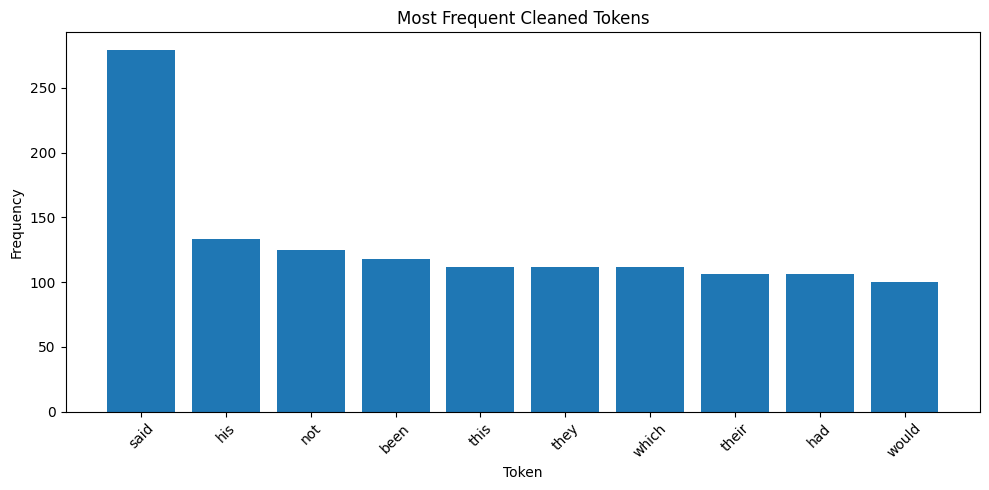

In [43]:
# Section 10 Python cell

top_df: pl.DataFrame = freq_df.head(10)

plt.figure(figsize=(10, 5))
plt.bar(top_df["token"], top_df["len"])

ax = plt.gca()
ax.tick_params(axis="x", labelrotation=45)

plt.title("Most Frequent Cleaned Tokens")
plt.xlabel("Token")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

## Section 11. Compare Raw vs Clean Token Counts

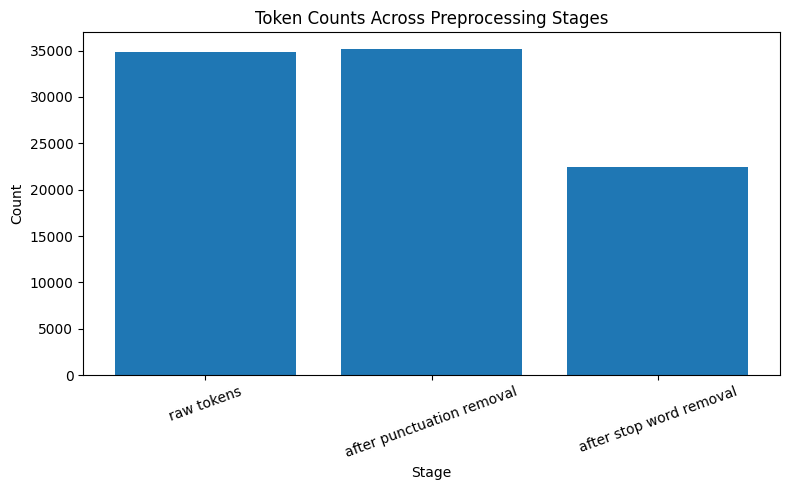

In [44]:
# Section 11 Python cell

plt.figure(figsize=(8, 5))
plt.bar(summary_df["stage"], summary_df["count"])

ax = plt.gca()
ax.tick_params(axis="x", labelrotation=20)

plt.title("Token Counts Across Preprocessing Stages")
plt.xlabel("Stage")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

## Section 12. Build a "Most Frequent Cleaned Tokens" Word Cloud

Sample of word frequencies:
said: 279
his: 133
not: 125
been: 118
this: 112
they: 112
which: 112
their: 106
had: 106
would: 100


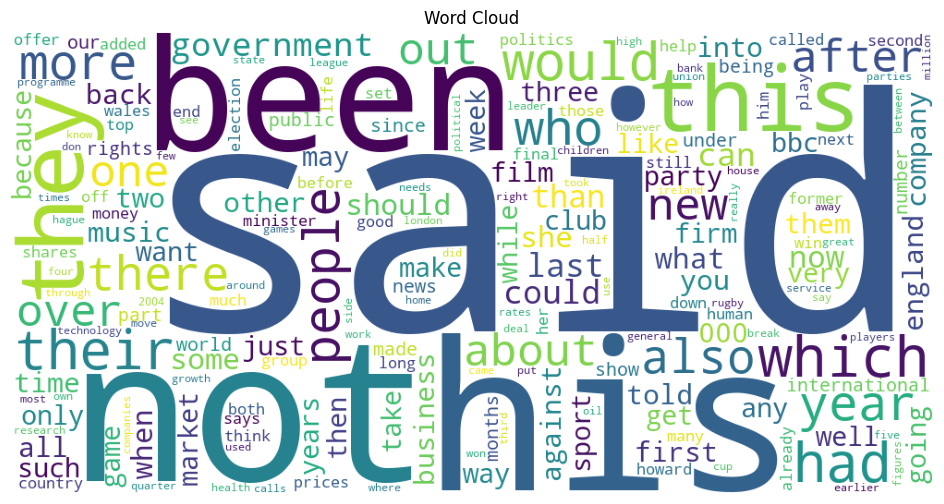

In [45]:
# Section 8 Python cell

# For this, we want a Python dictionary
# mapping words to their frequencies.
# We can use the zip() function to combine the "word" and "len" columns into a dictionary.
# First, convert the frequency dfs to lists with to_list(),
# then zip() them together into a dictionary.
# strict=True ensures both lists are the same length.
freq_dict = dict(zip(freq_df["token"].to_list(), freq_df["len"].to_list(), strict=True))
print("Sample of word frequencies:")
for word, freq in list(freq_dict.items())[:10]:
    print(f"{word}: {freq}")

# Build a word cloud where larger words occur more frequently in the text.
# Set width and height in pixels and set the background color.
wc: WordCloud = WordCloud(width=1000, height=500, background_color="white")

# Generate the word cloud from the frequency dictionary.
wc.generate_from_frequencies(freq_dict)

# Set the figure size in inches
plt.figure(figsize=(12, 6))

# Display the word cloud image with imshow() and turn off axes for a cleaner look.
plt.imshow(wc)
plt.axis("off")
plt.title("Word Cloud")
plt.show()

## Grouped Bar Chart of the Top Words from Each Category

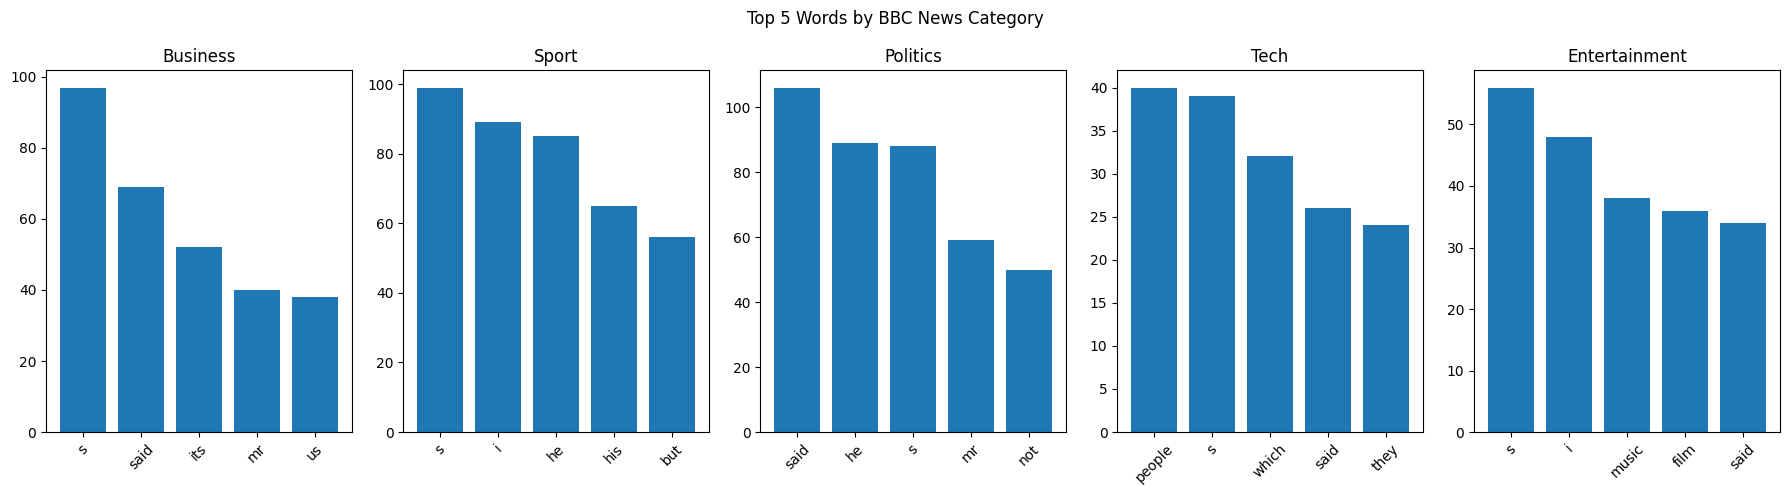

In [46]:
# Load data
# Path is defined earlier in the notebook as DATA_PATH = ROOT_PATH / "data"
data_file = DATA_PATH / "bbc-text.csv"
if not data_file.exists():
    data_file = Path.cwd() / "data" / "bbc-text.csv"

bbc_df = pl.read_csv(data_file)

# Categories to compare
categories = ["business", "sport", "politics", "tech", "entertainment"]

# Store most common word frequencies
top_words = {}

for category in categories:
    text = " ".join(
        bbc_df.filter(pl.col("category") == category)["text"].to_list()
    ).lower()

    tokens = re.findall(r"\b[a-z]+\b", text)

    # Optional stopword removal
    stopwords = {
        "the",
        "and",
        "to",
        "of",
        "a",
        "in",
        "is",
        "for",
        "that",
        "on",
        "with",
        "as",
        "at",
        "by",
        "an",
        "be",
        "are",
        "it",
        "from",
        "was",
        "has",
        "have",
    }

    tokens = [word for word in tokens if word not in stopwords]

    counts = Counter(tokens)

    top_words[category] = counts.most_common(5)

# Plot
fig, axes = plt.subplots(1, 5, figsize=(18, 5))

for ax, (category, words) in zip(axes, top_words.items()):
    labels = [word for word, count in words]
    values = [count for word, count in words]

    ax.bar(labels, values)
    ax.set_title(category.title())
    ax.tick_params(axis="x", rotation=45)

plt.suptitle("Top 5 Words by BBC News Category")
plt.tight_layout()
plt.show()

## Section 14: Data Insights
The word frequency analysis shows that common words such as "said," "not," "they," "his," and "this" appear most frequently throughout the BBC News dataset. These words are not specific to any one category (categories are business, sports, politices, tech and entertainment) and instead serve as general language used in news reporting. The prominence of "said" indicates that many articles rely on quotations and reported speech to convey information.